# Seclusion EDA — CRDC 2017-18 (school level)
**Task:** explore the cleaned CRDC data to understand seclusion patterns, data completeness, and how school characteristics, staffing and student population relate to seclusion; agree a target definition and feature shortlist.

**Scope of this notebook:** 2017-18 only (the three files supplied). Checklist items that need 2021-22 / 2020-21 data, or race/sex breakdowns of secluded students, cannot be done from these files; they are marked clearly in the relevant sections.

**Inputs:** `schools_201718.csv` (all schools), `schools_201718_analysis.csv` (rows with `flag_analysis_ready`), `quality_detail_201718.csv` (cleaning log).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60); pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

DATA_DIR = Path('/mnt/user-data/uploads')   # <- change to the repo data folder
ID = dtype={'combokey': str, 'leaid': str, 'schid': str}   # keep leading zeros
full = pd.read_csv(DATA_DIR/'schools_201718.csv', low_memory=False, **dict(dtype=ID))
ana  = pd.read_csv(DATA_DIR/'schools_201718_analysis.csv', low_memory=False, dtype=ID)
qlog = pd.read_csv(DATA_DIR/'quality_detail_201718.csv', low_memory=False, dtype=str)
print('full', full.shape, '| analysis', ana.shape, '| quality log', qlog.shape)

full (97632, 50) | analysis (91013, 50) | quality log (23648, 11)

## 1. Load and validate (checklist 1)
No preprocessing notes file was supplied, so I validate internal consistency: keys, counts, flags, derived fields, and the cleaning log.

In [2]:
checks = {
 'years present': full.year.unique().tolist(),
 'rows full / analysis': (len(full), len(ana)),
 'combokey unique (full)': full.combokey.is_unique,
 'combokey == leaid + schid (12 chars, zero-padded)': bool((full.combokey == full.leaid + full.schid).all() and full.combokey.str.len().eq(12).all()),
 'analysis rows all in full': bool(ana.combokey.isin(full.combokey).all()),
 'flag_analysis_ready == (~missing_secl & ~missing_enr)': bool((full.flag_analysis_ready == (~full.flag_missing_seclusion & ~full.flag_missing_enrollment)).all()),
 'analysis file == rows with flag_analysis_ready': int(full.flag_analysis_ready.sum()) == len(ana),
 'seclusion_instances == sum of 3 components (max abs diff)': float((full.seclusion_instances - full[['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']].sum(axis=1, min_count=3)).abs().max()),
 'seclusion_rate == instances/enrollment*100 (max abs diff)': float((full.seclusion_rate - full.seclusion_instances/full.enrollment_total*100).abs().max()),
 'states (incl. DC)': full.lea_state.nunique(), 'districts': full.leaid.nunique(),
}
pd.Series(checks, name='result').to_frame()

,result
years present,[2017-18]
rows full / analysis,"(97632, 91013)"
combokey unique (full),True
"combokey == leaid + schid (12 chars, zero-padded)",True
analysis rows all in full,True
flag_analysis_ready == (~missing_secl & ~missing_enr),True
analysis file == rows with flag_analysis_ready,True
seclusion_instances == sum of 3 components (max abs diff),0.000
seclusion_rate == instances/enrollment*100 (max abs diff),0.000
states (incl. DC),52


In [3]:
# Columns that are completely empty, and flags that never fire
empty_cols = full.columns[full.isna().all()].tolist()
dead_flags = [c for c in full.columns if c.startswith('flag_') and full[c].sum()==0]
print('Entirely empty columns :', empty_cols)
print('Flags that never fire  :', dead_flags)
print()
print('Flag counts (full file):'); print(full.filter(like='flag_').sum().to_string())

Entirely empty columns : ['enr_nonbinary', 'sch_virt_ind']
Flags that never fire  : ['flag_partial_enrollment', 'flag_partial_idea', 'flag_partial_504', 'flag_partial_el', 'flag_missing_module', 'flag_missing_lea']

Flag counts (full file):
flag_missing_seclusion      6619
flag_missing_enrollment       11
flag_small_enrollment       1212
flag_fte_outlier              68
flag_partial_enrollment        0
flag_partial_idea              0
flag_partial_504               0
flag_partial_el                0
flag_missing_module            0
flag_missing_lea               0
flag_analysis_ready        91013

In [4]:
# Reconcile the cleaning log with NaNs actually present in the schools file
set_na = qlog[qlog.action.eq('set_na')].groupby('raw_column').size()
mapping = {'SCH_RSINSTANCES_SECL_WODIS':'seclusion_instances_wodis','SCH_RSINSTANCES_SECL_IDEA':'seclusion_instances_idea',
           'SCH_RSINSTANCES_SECL_504':'seclusion_instances_504','SCH_FTESECURITY_GUA':'fte_guards','SCH_FTESECURITY_LEO':'fte_leo',
           'SCH_FTESERVICES_NUR':'fte_nurses','SCH_FTESERVICES_PSY':'fte_psych','SCH_FTESERVICES_SOC':'fte_social',
           'SCH_FTECOUNSELORS':'fte_counselors','SCH_FTETEACH_TOT':'fte_teachers'}
rec = pd.DataFrame({'log_set_na': {v: set_na.get(k, 0) for k, v in mapping.items()},
                    'nan_in_full_file': {v: int(full[v].isna().sum()) for v in mapping.values()}})
rec['diff'] = rec.log_set_na - rec.nan_in_full_file
print('Log rows with no combokey (LEA-level entries):', int(qlog.combokey.isna().sum()), '| log rows with a combokey missing from the schools file:', int((qlog.combokey.notna() & ~qlog.combokey.isin(full.combokey)).sum()), 'of', len(qlog))
rec

Log rows with no combokey (LEA-level entries): 1 | log rows with a combokey missing from the schools file: 0 of 23648

,log_set_na,nan_in_full_file,diff
seclusion_instances_wodis,6491,6491,0
seclusion_instances_idea,6082,6082,0
seclusion_instances_504,6252,6252,0
fte_guards,2207,2207,0
fte_leo,1615,1615,0
fte_nurses,21,21,0
fte_psych,21,21,0
fte_social,21,21,0
fte_counselors,21,21,0
fte_teachers,21,21,0


## 2. Missing values (checklist 2)
Only one school year is present, so 'per year' is a single row. Seclusion is missing when any of the three component counts is a CRDC reserved code (set to NA by cleaning).

In [5]:
miss = pd.DataFrame({'n_missing': full.isna().sum(), 'pct_missing': full.isna().mean()*100})
miss = miss[miss.n_missing > 0].sort_values('pct_missing', ascending=False)
miss

,n_missing,pct_missing
enr_nonbinary,97632,100.000
sch_virt_ind,97632,100.000
seclusion_instances,6619,6.780
seclusion_rate,6619,6.780
seclusion_instances_wodis,6491,6.648
seclusion_instances_504,6252,6.404
seclusion_instances_idea,6082,6.230
fte_guards,2207,2.261
fte_leo,1615,1.654
pct_idea,233,0.239


Number of missing seclusion components per school:
0    91013
1      342
2      348
3     5929

Schools with total missing but >=1 observed component > 0 (lower bound is known): 226
Schools with total missing, 1-2 components missing, all observed components == 0: 464

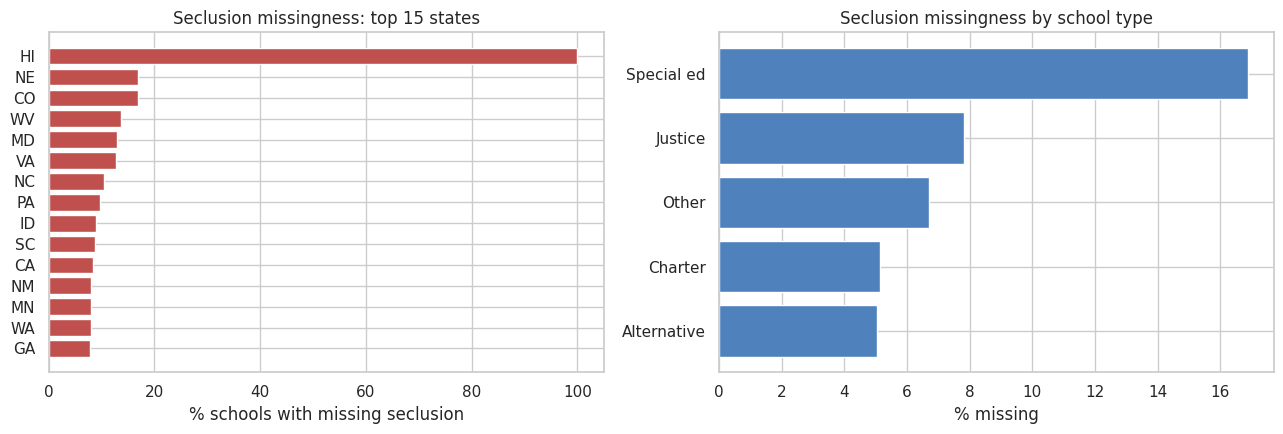

In [6]:
# How is seclusion missingness structured?
comp = ['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']
n_comp_missing = full[comp].isna().sum(axis=1)
print('Number of missing seclusion components per school:'); print(n_comp_missing.value_counts().sort_index().to_string())
part = full[full.seclusion_instances.isna() & (full[comp].fillna(0).sum(axis=1) > 0)]
print(f'\nSchools with total missing but >=1 observed component > 0 (lower bound is known): {len(part)}')
print(f'Schools with total missing, 1-2 components missing, all observed components == 0: {int(((n_comp_missing.between(1,2)) & (full[comp].fillna(0).sum(axis=1)==0)).sum())}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
st = full.groupby('lea_state').flag_missing_seclusion.agg(['mean','sum']).sort_values('mean', ascending=False).head(15)
ax[0].barh(st.index[::-1], st['mean'][::-1]*100, color='#c0504d'); ax[0].set_xlabel('% schools with missing seclusion'); ax[0].set_title('Seclusion missingness: top 15 states')
tmp = full.assign(type=np.select([full.sch_status_sped.eq('Yes'), full.jj.eq('Yes'), full.sch_status_alt.eq('Yes'), full.sch_status_charter.eq('Yes')], ['Special ed','Justice','Alternative','Charter'], 'Other'))
t = tmp.groupby('type').flag_missing_seclusion.mean().sort_values()*100
ax[1].barh(t.index, t.values, color='#4f81bd'); ax[1].set_xlabel('% missing'); ax[1].set_title('Seclusion missingness by school type'); plt.tight_layout()

In [7]:
# Does dropping missing rows bias the analysis file? (full-file profile of missing vs non-missing)
prof = full.assign(any_flag=full.flag_missing_seclusion).groupby('any_flag').agg(
    n=('combokey','size'), median_enr=('enrollment_total','median'), mean_pct_idea=('pct_idea','mean'),
    pct_sped=('sch_status_sped', lambda s:(s=='Yes').mean()*100), pct_charter=('sch_status_charter', lambda s:(s=='Yes').mean()*100),
    pct_alt=('sch_status_alt', lambda s:(s=='Yes').mean()*100), pct_jj=('jj', lambda s:(s=='Yes').mean()*100))
prof

,n,median_enr,mean_pct_idea,pct_sped,pct_charter,pct_alt,pct_jj
any_flag,,,,,,,
False,91013,440.000,15.074,2.019,7.352,3.486,0.610
True,6619,397.000,19.388,5.635,5.409,2.568,0.710


## 3. Distribution of seclusion instances and rates (checklist 3)
`seclusion_rate` = instances per 100 enrolled students (instances are **events**, not students, so it can exceed 100).

In [8]:
df = ana.copy()
df['any_secl'] = (df.seclusion_instances > 0).astype(int)
x = df.seclusion_instances; r = df.seclusion_rate
print(f'Schools in analysis file: {len(df):,}')
print(f'Zero seclusion: {(x==0).mean():.2%} | any seclusion: {(x>0).mean():.2%} ({(x>0).sum():,} schools)')
print(f'Total instances: {x.sum():,.0f}; mean {x.mean():.3f}; skew {x.skew():.1f}; kurtosis {x.kurt():.0f}')
print('\nInstance quantiles (all schools):', x.quantile([.5,.9,.95,.975,.99,.999]).round(1).to_dict())
pos = df[df.any_secl==1]
print('\nAmong schools with >=1 instance:'); print(pos.seclusion_instances.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
print('\nRate (per 100 students) among positives:'); print(pos.seclusion_rate.describe(percentiles=[.25,.5,.75,.9,.95,.99]).round(2).to_string())
srt = x.sort_values(ascending=False).cumsum()/x.sum()
for k in (10, 50, 100, 500, 1000): print(f'Top {k:>4} schools hold {srt.iloc[k-1]:.1%} of all instances')
print(f'Schools with rate > 100 per 100 students: {(r>100).sum()}  | rate > 25: {(r>25).sum()}')

Schools in analysis file: 91,013
Zero seclusion: 93.44% | any seclusion: 6.56% (5,975 schools)
Total instances: 141,989; mean 1.560; skew 30.6; kurtosis 1359

Instance quantiles (all schools): {0.5: 0.0, 0.9: 0.0, 0.95: 2.0, 0.975: 8.0, 0.99: 33.0, 0.999: 239.0}

Among schools with >=1 instance:
count   5,975.000
mean       23.760
std        67.740
min         1.000
25%         2.000
50%         5.000
75%        17.000
90%        54.000
95%       106.000
99%       316.420
max     1,252.000

Rate (per 100 students) among positives:
count   5,975.000
mean       16.900
std       107.600
min         0.030
25%         0.340
50%         1.130
75%         4.440
90%        17.690
95%        44.440
99%       354.030
max     3,250.000
Top   10 schools hold 6.9% of all instances
Top   50 schools hold 20.3% of all instances
Top  100 schools hold 30.0% of all instances
Top  500 schools hold 62.8% of all instances
Top 1000 schools hold 78.2% of all instances
Schools with rate > 100 per 100 students:

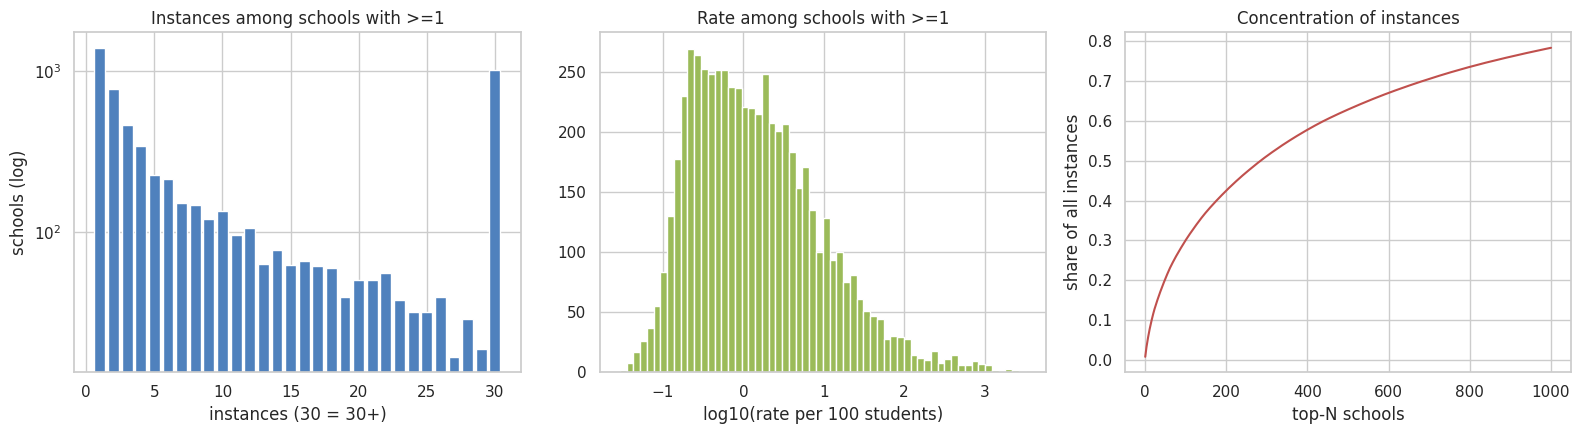

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
vc = pos.seclusion_instances.clip(upper=30).value_counts().sort_index()
ax[0].bar(vc.index.astype(int), vc.values, color='#4f81bd'); ax[0].set_yscale('log'); ax[0].set_xlabel('instances (30 = 30+)'); ax[0].set_ylabel('schools (log)'); ax[0].set_title('Instances among schools with >=1')
ax[1].hist(np.log10(pos.seclusion_rate), bins=60, color='#9bbb59'); ax[1].set_xlabel('log10(rate per 100 students)'); ax[1].set_title('Rate among schools with >=1')
ax[2].plot(np.arange(1, 1001), srt.values[:1000], color='#c0504d'); ax[2].set_xlabel('top-N schools'); ax[2].set_ylabel('share of all instances'); ax[2].set_title('Concentration of instances'); plt.tight_layout()

In [10]:
cols = ['sch_name','lea_name','lea_state','enrollment_total','seclusion_instances','seclusion_rate','sch_status_sped','sch_status_alt','jj']
print('Top 12 by instances'); display_top = df.nlargest(12, 'seclusion_instances')[cols]; print(display_top.to_string(index=False))
print('\nTop 12 by rate'); print(df.nlargest(12, 'seclusion_rate')[cols].to_string(index=False))

Top 12 by instances
                                   sch_name                                    lea_name lea_state  enrollment_total  seclusion_instances  seclusion_rate sch_status_sped sch_status_alt jj
River Street Early Learning Center (Site 2)               CAPITOL REGION EDUCATION COUN        CT            66.000            1,252.000       1,896.970             Yes             No No
                  Smouse Opportunity School Des Moines Independent Comm School District        IA            94.000            1,224.000       1,302.128              No             No No
                      Ruby Van Meter School Des Moines Independent Comm School District        IA           137.000            1,165.000         850.365              No             No No
                      MCESC LEARNING CENTER                       Montgomery County ESC        OH           105.000            1,006.000         958.095             Yes             No No
                  Piedmont REG ED/IVY CREEK  

## 4. Share reporting any seclusion and a threshold for "elevated" (checklist 4)

In [11]:
tiers = pd.DataFrame({'schools': [(x>=k).sum() for k in (1,2,3,5,10,20,50)], 'share_of_schools': [(x>=k).mean() for k in (1,2,3,5,10,20,50)],
                     'share_of_instances': [x[x>=k].sum()/x.sum() for k in (1,2,3,5,10,20,50)]}, index=[f'>= {k} instances' for k in (1,2,3,5,10,20,50)])
print(tiers.to_string())
# rate-based alternatives restricted to enrollment >= 30 (see section 9)
big = df[df.enrollment_total >= 30]
print('\nRate thresholds (enrollment >= 30): p90/p95/p99 among positives =', big[big.any_secl==1].seclusion_rate.quantile([.9,.95,.99]).round(2).to_dict())
print('Schools with rate >= 1 per 100 :', (big.seclusion_rate>=1).sum(), f'({(big.seclusion_rate>=1).mean():.2%})')
print('Schools with rate >= 5 per 100 :', (big.seclusion_rate>=5).sum(), f'({(big.seclusion_rate>=5).mean():.2%})')
print('Schools with >=5 instances AND rate >= 1 : ', ((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).sum(), f'({((big.seclusion_instances>=5)&(big.seclusion_rate>=1)).mean():.2%})')

                 schools  share_of_schools  share_of_instances
>= 1 instances      5975             0.066               1.000
>= 2 instances      4585             0.050               0.990
>= 3 instances      3811             0.042               0.979
>= 5 instances      3006             0.033               0.960
>= 10 instances     2147             0.024               0.919
>= 20 instances     1375             0.015               0.845
>= 50 instances      655             0.007               0.689

Rate thresholds (enrollment >= 30): p90/p95/p99 among positives = {0.9: 15.19, 0.95: 33.93, 0.99: 210.78}
Schools with rate >= 1 per 100 : 3033 (3.46%)
Schools with rate >= 5 per 100 : 1305 (1.49%)
Schools with >=5 instances AND rate >= 1 :  2710 (3.09%)

In [12]:
# Is 'any' a one-off or a pattern? How does the share of schools with 1,2,3+ instances look within the positive group?
print((pos.seclusion_instances.clip(upper=10)).value_counts(normalize=True).sort_index().round(3).to_string())
# Which component drives it?
comp_tot = ana[['seclusion_instances_idea','seclusion_instances_504','seclusion_instances_wodis']].sum()
print('\nInstance totals by student group:'); print((comp_tot/comp_tot.sum()).round(4).to_string())
print('\nSchools with any instance, by group:', {c.replace('seclusion_instances_',''): int((ana[c]>0).sum()) for c in comp_tot.index})

seclusion_instances
1.000    0.233
2.000    0.130
3.000    0.077
4.000    0.058
5.000    0.038
6.000    0.036
7.000    0.025
8.000    0.025
9.000    0.020
10.000   0.359

Instance totals by student group:
seclusion_instances_idea    0.859
seclusion_instances_504     0.010
seclusion_instances_wodis   0.131

Schools with any instance, by group: {'idea': 5371, '504': 199, 'wodis': 2009}

## 5. School types and grade levels (checklist 5)

In [13]:
df['type_sped']=df.sch_status_sped.eq('Yes'); df['type_alt']=df.sch_status_alt.eq('Yes'); df['type_charter']=df.sch_status_charter.eq('Yes')
df['type_magnet']=df.sch_status_magnet.eq('Yes'); df['type_jj']=df.jj.eq('Yes')
df['type_virtual_name'] = df.sch_name.str.contains(r'virtual|online|cyber|e-?learning|distance', case=False, na=False)   # PROXY: sch_virt_ind is 100% empty
df['regular'] = ~(df.type_sped | df.type_alt | df.type_jj)
df['enr_ge30'] = df.enrollment_total >= 30

def summ(d, by):
    g = d.groupby(by)
    out = pd.DataFrame({'schools': g.size(), 'pct_any_secl': g.any_secl.mean()*100,
        'mean_instances': g.seclusion_instances.mean(),
        'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
        'share_of_all_instances_%': g.seclusion_instances.sum()/d.seclusion_instances.sum()*100})
    return out

rows = []
for col, lab in [('type_sped','Special education'),('type_alt','Alternative'),('type_charter','Charter'),('type_magnet','Magnet'),('type_jj','Justice facility'),('type_virtual_name','Virtual (name proxy)')]:
    t_ = summ(df, col); t_.index = t_.index.map({True: 'Yes', False: 'No'})
    rows += [t_.loc[['Yes']].rename(index={'Yes': lab}), t_.loc[['No']].rename(index={'No': lab + ' = No'})]
type_tbl = pd.concat(rows); type_tbl

,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
Special education,1838,16.594,18.170,44.681,23.520
Special education = No,89175,6.358,1.218,1.000,76.480
Alternative,3173,1.954,0.730,11.146,1.632
Alternative = No,87840,6.732,1.590,1.117,98.368
Charter,6691,2.825,0.479,1.000,2.257
Charter = No,84322,6.862,1.646,1.136,97.743
Magnet,3870,4.651,0.444,0.426,1.211
Magnet = No,87143,6.650,1.610,1.176,98.789
Justice facility,555,7.928,3.074,62.273,1.202
Justice facility = No,90458,6.557,1.551,1.115,98.798


,schools,pct_any_secl,mean_instances,median_rate_if_any,share_of_all_instances_%
grade_band,,,,,
elementary,34560,8.863,2.038,1.487,49.608
high,16452,2.857,0.313,0.283,3.625
middle,12469,5.077,0.606,0.465,5.325
other,257,10.506,9.109,26.316,1.649
span,27275,6.533,2.072,1.356,39.793


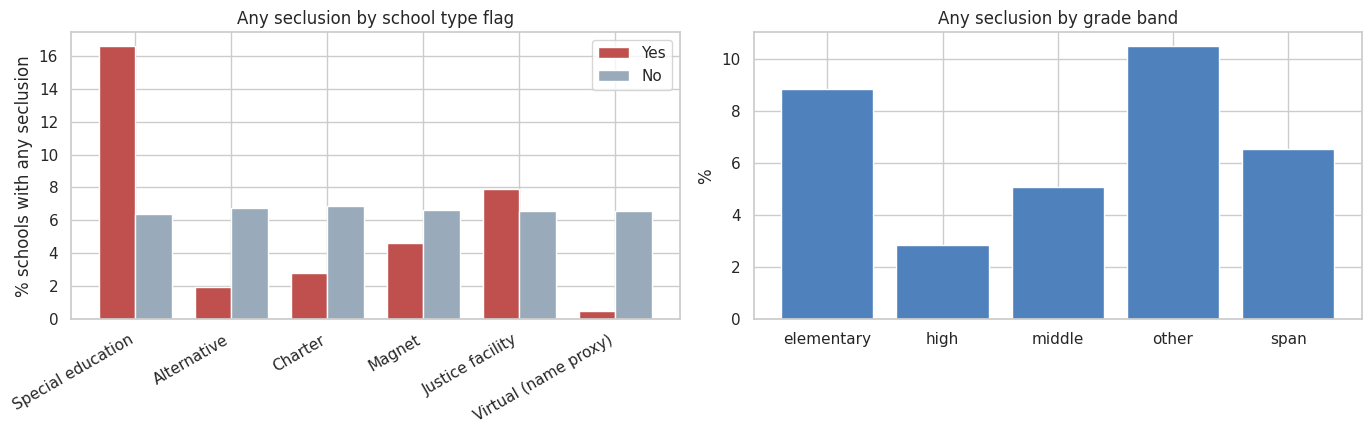

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
labs = ['Special education','Alternative','Charter','Magnet','Justice facility','Virtual (name proxy)']; cols = ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']
yes = [df.loc[df[c],'any_secl'].mean()*100 for c in cols]; no = [df.loc[~df[c],'any_secl'].mean()*100 for c in cols]
w=.38; i=np.arange(len(cols)); ax[0].bar(i-w/2, yes, w, label='Yes', color='#c0504d'); ax[0].bar(i+w/2, no, w, label='No', color='#9ab'); ax[0].set_xticks(i); ax[0].set_xticklabels(labs, rotation=30, ha='right'); ax[0].set_ylabel('% schools with any seclusion'); ax[0].legend(); ax[0].set_title('Any seclusion by school type flag')
gb = summ(df, 'grade_band'); ax[1].bar(gb.index, gb.pct_any_secl, color='#4f81bd'); ax[1].set_title('Any seclusion by grade band'); ax[1].set_ylabel('%')
plt.tight_layout(); gb

In [15]:
# Grade band within regular schools only (removes the special-ed / alternative / justice effect) and type x grade
print('Regular schools (not sped / alt / justice) by grade band'); print(summ(df[df.regular], 'grade_band').round(2).to_string())
print('\nShare of the 5,975 schools with any seclusion that are...')
pos = df[df.any_secl==1]
print({k: f'{pos[k].mean():.1%} (vs {df[k].mean():.1%} of all schools)' for k in ['type_sped','type_alt','type_charter','type_magnet','type_jj','type_virtual_name']})
print('\nRegular school share of positives:', f'{pos.regular.mean():.1%}')

Regular schools (not sped / alt / justice) by grade band
            schools  pct_any_secl  mean_instances  median_rate_if_any  share_of_all_instances_%
grade_band                                                                                     
elementary    34296         8.830           1.960               1.460                    63.880
high          14508         3.050           0.320               0.260                     4.330
middle        12318         5.070           0.580               0.450                     6.760
other            70         0.000           0.000                 NaN                     0.000
span          24575         6.050           1.070               0.920                    25.030

Share of the 5,975 schools with any seclusion that are...
{'type_sped': '5.1% (vs 2.0% of all schools)', 'type_alt': '1.0% (vs 3.5% of all schools)', 'type_charter': '3.2% (vs 7.4% of all schools)', 'type_magnet': '3.0% (vs 4.3% of all schools)', 'type_jj': '0.7% (vs 0.

## 6. States and districts (checklist 6)

In [16]:
stt = df.groupby('lea_state').agg(schools=('combokey','size'), pct_any=('any_secl', lambda s: s.mean()*100), instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum'))
stt['instances_per_1000_students'] = stt.instances/stt.enroll*1000
stt['pct_missing_in_full_file'] = full.groupby('lea_state').flag_missing_seclusion.mean()*100
stt = stt.sort_values('pct_any', ascending=False)
print('Top 10 / bottom 12 states by % schools with any seclusion'); print(pd.concat([stt.head(10), stt.tail(12)]).round(2).to_string())
print('\nStates with 0 schools reporting any seclusion:', stt.index[stt.pct_any==0].tolist())
print('Median state % any:', round(stt.pct_any.median(),2), '| IQR', stt.pct_any.quantile([.25,.75]).round(2).tolist())

Top 10 / bottom 12 states by % schools with any seclusion
           schools  pct_any  instances        enroll  instances_per_1000_students  pct_missing_in_full_file
lea_state                                                                                                  
WI            2122   33.220 10,774.000   835,172.000                       12.900                     5.060
IA            1291   29.740 17,525.000   494,974.000                       35.410                     3.870
ME             566   27.740  3,789.000   172,983.000                       21.900                     2.250
CT            1124   26.960  8,300.000   504,534.000                       16.450                     7.410
KS            1317   22.930  8,051.000   473,902.000                       16.990                     2.440
WA            2153   20.070 11,131.000 1,067,773.000                       10.420                     7.950
VT             295   18.980    977.000    81,849.000                       11.

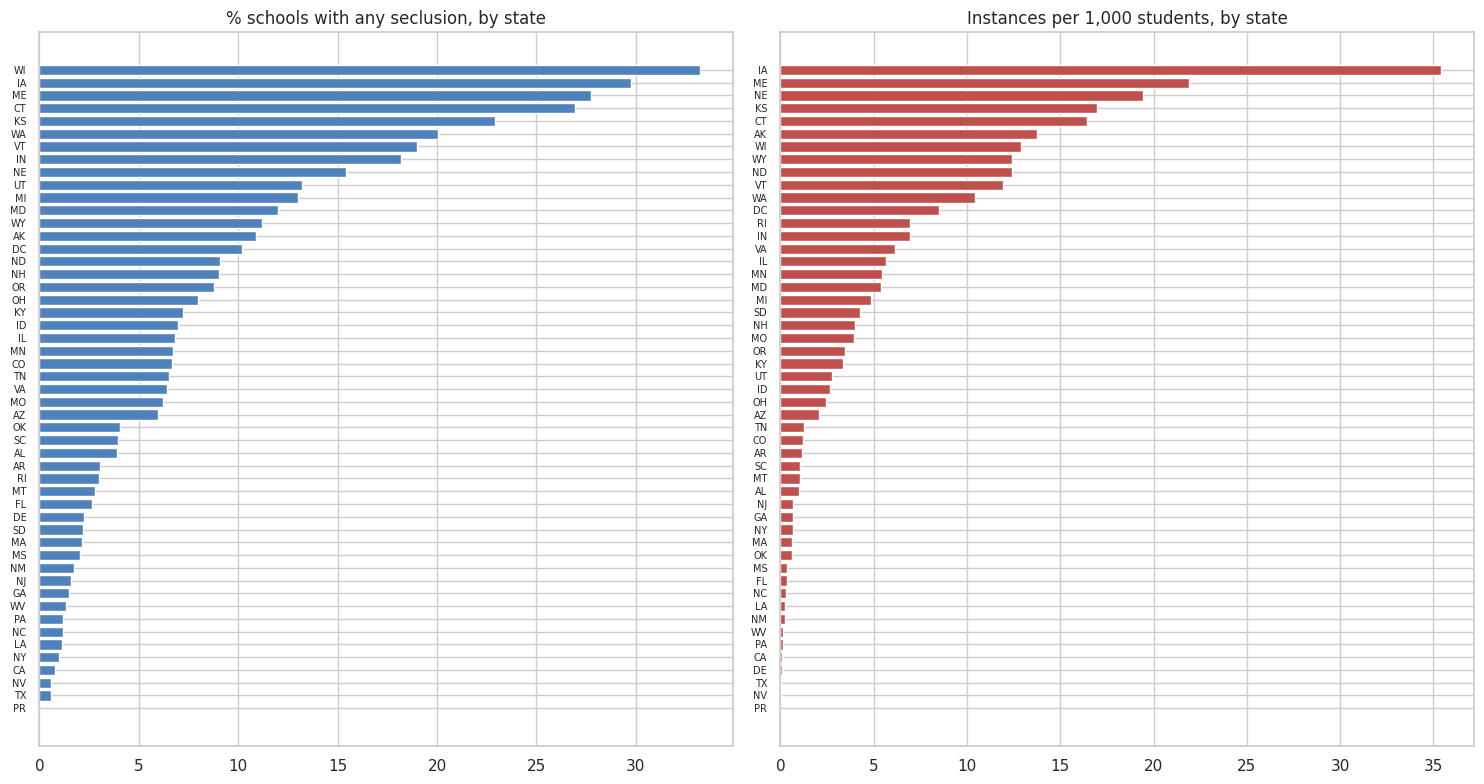

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
s = stt.sort_values('pct_any'); ax[0].barh(s.index, s.pct_any, color='#4f81bd'); ax[0].set_title('% schools with any seclusion, by state'); ax[0].tick_params(axis='y', labelsize=7)
s = stt.sort_values('instances_per_1000_students'); ax[1].barh(s.index, s.instances_per_1000_students, color='#c0504d'); ax[1].set_title('Instances per 1,000 students, by state'); ax[1].tick_params(axis='y', labelsize=7); plt.tight_layout()

Districts: 17,212; with >=1 school reporting any seclusion: 2,213 (12.9%)
Top  10 districts = 15.1% of instances
Top  50 districts = 37.9% of instances
Top 100 districts = 52.8% of instances
Top 500 districts = 87.3% of instances
Districts that account for 50% of instances: 89; for 80%: 339
                                            lea_name state  schools  schools_any  instances      enroll  share_instances_%  cum_share_%
leaid                                                                                                                                  
1908970  Des Moines Independent Comm School District    IA       57           36  3,458.000  32,271.000              2.400        2.400
5100020                     SOUTHEASTERN COOP ED PGM    VA        5            5  3,120.000     365.000              2.200        4.600
3172840                       LINCOLN PUBLIC SCHOOLS    NE       66           53  2,863.000  40,755.000              2.000        6.600
5308250                     

(0.0, 10.0)

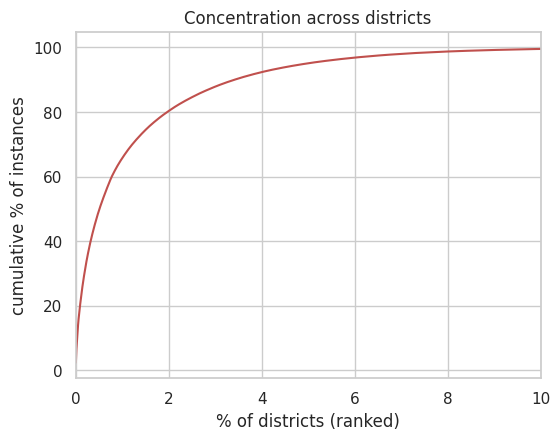

In [18]:
dist = df.groupby(['leaid']).agg(lea_name=('lea_name','first'), state=('lea_state','first'), schools=('combokey','size'), schools_any=('any_secl','sum'),
                                  instances=('seclusion_instances','sum'), enroll=('enrollment_total','sum')).sort_values('instances', ascending=False)
dist['share_instances_%'] = dist.instances/dist.instances.sum()*100; dist['cum_share_%'] = dist['share_instances_%'].cumsum()
print(f'Districts: {len(dist):,}; with >=1 school reporting any seclusion: {(dist.schools_any>0).sum():,} ({(dist.schools_any>0).mean():.1%})')
for k in (10, 50, 100, 500): print(f'Top {k:>3} districts = {dist.instances.iloc[:k].sum()/dist.instances.sum():.1%} of instances')
print(f'Districts that account for 50% of instances: {(dist["cum_share_%"]<50).sum()+1}; for 80%: {(dist["cum_share_%"]<80).sum()+1}')
print(dist.head(15).round(1).to_string())
fig, ax = plt.subplots(figsize=(6,4.5)); d2 = dist[dist.instances>0]; ax.plot(np.arange(1,len(d2)+1)/len(dist)*100, d2['cum_share_%'].values, color='#c0504d'); ax.set_xlabel('% of districts (ranked)'); ax.set_ylabel('cumulative % of instances'); ax.set_title('Concentration across districts'); ax.set_xlim(0,10)

In [19]:
# Within-state vs between-state: how much of 'any seclusion' is explained by state alone, and by district?
from sklearn.metrics import roc_auc_score
st_mean = df.groupby('lea_state').any_secl.transform('mean'); print('AUC of state-mean alone    :', round(roc_auc_score(df.any_secl, st_mean),3))
lea_mean = df.groupby('leaid').any_secl.transform('mean'); print('AUC of district-mean (in-sample, optimistic, leaky):', round(roc_auc_score(df.any_secl, lea_mean),3))
print('Positives sitting in districts where >=50% of schools are positive:', f"{pos.leaid.map(df.groupby('leaid').any_secl.mean()).ge(.5).mean():.1%}")
print('Single-school districts among positives:', f"{(pos.leaid.map(df.groupby('leaid').size())==1).mean():.1%}")

AUC of state-mean alone    : 0.809
AUC of district-mean (in-sample, optimistic, leaky): 0.965
Positives sitting in districts where >=50% of schools are positive: 46.8%
Single-school districts among positives: 4.7%

## 7. Staffing and seclusion (checklist 7)
Per-100 ratios are rebuilt from the FTE counts, with rows flagged `flag_fte_outlier` excluded and ratios capped at the 99.5th percentile, because several FTE values are impossible (e.g. 19,048.6 psychologists at one school — see Data Issues).

In [20]:
st = df[~df.flag_fte_outlier & df.enrollment_total.ge(30)].copy()
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    st[f'{c}_p100'] = st[f'fte_{c}']/st.enrollment_total*100
    st[f'{c}_p100'] = st[f'{c}_p100'].clip(upper=st[f'{c}_p100'].quantile(.995))
# sanity: what is support_fte_per_100?
chk = (st.fte_counselors+st.fte_psych+st.fte_social+st.fte_nurses)/st.enrollment_total*100
print('support_fte_per_100 == counselors+psych+social+nurses per 100? corr =', round(np.corrcoef(chk.fillna(0), st.support_fte_per_100.fillna(0))[0,1],4), '| max abs diff on 99% of rows =', round((chk-st.support_fte_per_100).abs().quantile(.99),4))
staff = ['counselors','psych','social','nurses','leo','guards']
out = []
for c in staff:
    for lab, d in [('All (enr>=30)', st), ('Regular schools', st[st.regular])]:
        d = d.dropna(subset=[f'fte_{c}'])
        has = d[f'fte_{c}']>0
        pos_p = d.loc[has, f'{c}_p100']; terc = pd.qcut(pos_p, 3, labels=['low','mid','high'], duplicates='drop')
        r = {'staff': c, 'sample': lab, 'share_with_any_FTE_%': has.mean()*100, 'any_secl_%_none': d.loc[~has,'any_secl'].mean()*100}
        for t in ['low','mid','high']: r[f'any_secl_%_{t}'] = d.loc[pos_p.index[terc==t],'any_secl'].mean()*100
        out.append(r)
staff_tbl = pd.DataFrame(out).set_index(['staff','sample']); staff_tbl.round(2)

support_fte_per_100 == counselors+psych+social+nurses per 100? corr = 0.8489 | max abs diff on 99% of rows = 1.7241

share_with_any_FTE_%  any_secl_%_none  any_secl_%_low  any_secl_%_mid  any_secl_%_high
staff      sample                                                                                                 
counselors All (enr>=30)                  76.280            7.600           7.360           7.150            4.750
           Regular schools                77.270            7.210           7.350           7.250            4.730
psych      All (enr>=30)                  47.240            5.170           7.480           9.220            8.530
           Regular schools                47.720            5.070           7.510           9.270            8.170
social     All (enr>=30)                  31.810            5.560           8.660          10.020            8.750
           Regular schools                31.740            5.550           8.530          10.170            8.050
nurses     All (enr>=30)                  66.460            5.310           8.020           6.770            7.410
           Regular schools                67.450            5.330           8.100           6.800            6.810
leo        All (enr>=30)                  25.260            6.740           9.460           6.710            5.040
           Regular schools                25.520            6.650           9.560           6.770            4.700
guards     All (enr>=30)                  14.090            7.000           8.620           4.650            3.850
           Regular schools                13.880            6.920           8.640           4.920            3.330

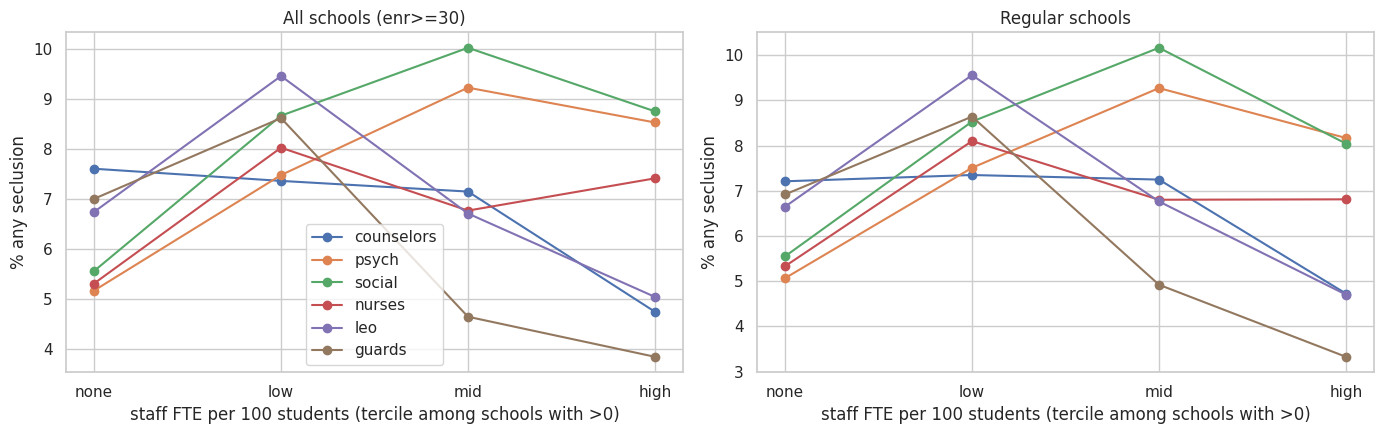

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (lab, d) in zip(axes, [('All schools (enr>=30)', st), ('Regular schools', st[st.regular])]):
    for c in staff:
        dd = d.dropna(subset=[f'fte_{c}']); has = dd[f'fte_{c}']>0; pp = dd.loc[has, f'{c}_p100']; t = pd.qcut(pp, 3, labels=['low','mid','high'], duplicates='drop')
        vals = [dd.loc[~has,'any_secl'].mean()*100] + [dd.loc[pp.index[t==k],'any_secl'].mean()*100 for k in ['low','mid','high']]
        ax.plot(['none','low','mid','high'], vals, marker='o', label=c)
    ax.set_title(lab); ax.set_ylabel('% any seclusion'); ax.set_xlabel('staff FTE per 100 students (tercile among schools with >0)')
axes[0].legend(); plt.tight_layout()

In [22]:
# Staffing relationship after controlling for size, school type, grade band and population (logistic regression, standardised)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
X = st[st.regular].dropna(subset=['pct_idea','pct_el','pct_504']+[f'{c}_p100' for c in staff]).copy()
feat = ['log_enr','pct_idea','pct_504','pct_el']+[f'{c}_p100' for c in staff]
X['log_enr'] = np.log(X.enrollment_total)
Xd = pd.concat([X[feat], pd.get_dummies(X.grade_band, drop_first=True, dtype=float)], axis=1)
m = LogisticRegression(max_iter=2000, C=1.0).fit(StandardScaler().fit_transform(Xd), X.any_secl)
coef = pd.Series(m.coef_[0], index=Xd.columns).sort_values(); print('Standardised log-odds coefficients (regular schools, enr>=30):'); coef.round(3)

Standardised log-odds coefficients (regular schools, enr>=30):

,0
high,-0.445
pct_el,-0.234
pct_504,-0.218
middle,-0.207
span,-0.163
guards_p100,-0.134
other,-0.082
leo_p100,-0.056
nurses_p100,-0.027
counselors_p100,-0.007


## 8. Student population and seclusion (checklist 8)

pct_idea
                size  pct_any
pct_idea_bin                 
(-0.1, 5.0]     4649    2.130
(5.0, 10.0]    19075    4.840
(10.0, 15.0]   31497    6.930
(15.0, 20.0]   18243    8.490
(20.0, 30.0]    8916    8.210
(30.0, 50.0]    1542    4.220
(50.0, 100.1]    173    8.090 

pct_504
                size  pct_any
pct_504_bin                  
(-0.1, 0.5]    24639    6.020
(0.5, 2.0]     24379    8.680
(2.0, 5.0]     22640    6.680
(5.0, 10.0]    10024    3.960
(10.0, 100.1]   2413    2.240 

pct_el
                size  pct_any
pct_el_bin                   
(-0.1, 1.0]    26034    5.370
(1.0, 5.0]     22610    8.080
(5.0, 15.0]    17927    7.650
(15.0, 40.0]   12944    6.360
(40.0, 100.1]   4580    3.140 

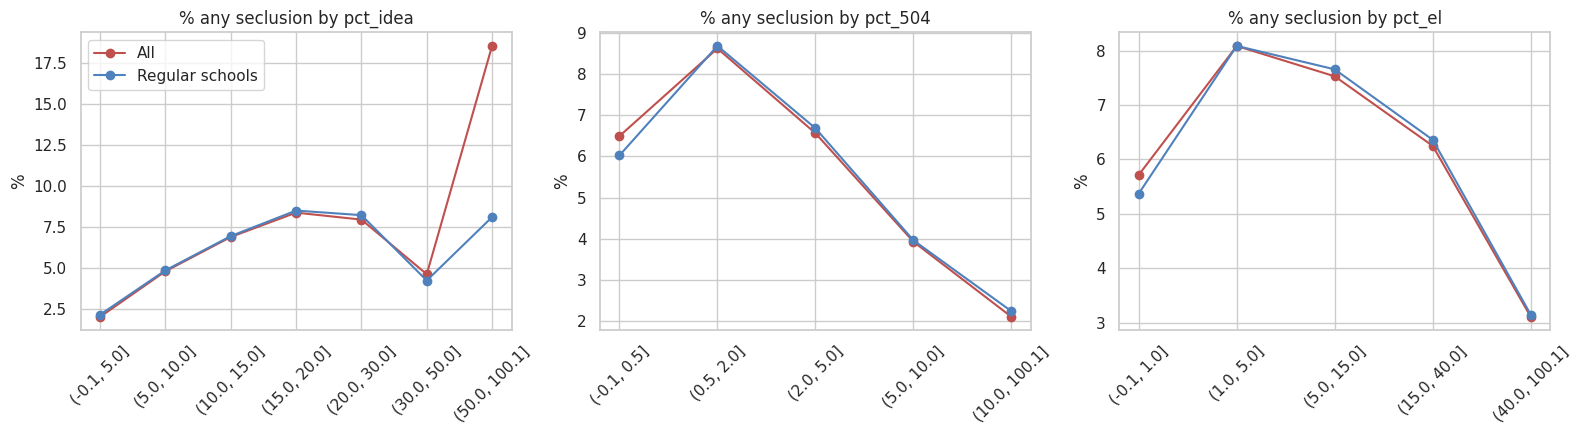

In [23]:
pp = df[df.enr_ge30 & df.pct_idea.notna() & df.pct_el.notna() & df.pct_504.notna()].copy()
bins = {'pct_idea':[-.1,5,10,15,20,30,50,100.1], 'pct_504':[-.1,.5,2,5,10,100.1], 'pct_el':[-.1,1,5,15,40,100.1]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5)); res = {}
for ax, (c, b) in zip(axes, bins.items()):
    pp[c+'_bin'] = pd.cut(pp[c], b)
    for lab, d, col in [('All', pp, '#c0504d'), ('Regular schools', pp[pp.regular], '#4f81bd')]:
        g = d.groupby(c+'_bin', observed=True).any_secl.agg(['mean','size']); ax.plot(g.index.astype(str), g['mean']*100, marker='o', label=lab, color=col); res[(c, lab)] = g
    ax.set_title(f'% any seclusion by {c}'); ax.tick_params(axis='x', rotation=45); ax.set_ylabel('%')
axes[0].legend(); plt.tight_layout()
for k, v in res.items():
    if k[1]=='Regular schools': print(k[0]); print((v.assign(**{'pct_any': v['mean']*100}).drop(columns='mean')).round(2).to_string(), '\n')

In [24]:
sp = pp[['any_secl','pct_idea','pct_504','pct_el','seclusion_rate','enrollment_total']].copy(); sp['log_enr']=np.log(sp.enrollment_total)
print('Spearman with any_secl (all, enr>=30):'); print(sp.corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
r_ = pp[pp.regular]; print('\nSpearman with any_secl (regular schools):'); print(r_[['any_secl','pct_idea','pct_504','pct_el']].corr(method='spearman')['any_secl'].drop('any_secl').round(3).to_string())
print('\nRegular schools, any_secl by whether %IDEA is above regular-school median:', r_.groupby(r_.pct_idea>r_.pct_idea.median()).any_secl.mean().mul(100).round(2).to_dict())

Spearman with any_secl (all, enr>=30):
pct_idea            0.068
pct_504            -0.029
pct_el              0.003
seclusion_rate      0.999
enrollment_total    0.012
log_enr             0.012

Spearman with any_secl (regular schools):
pct_idea    0.060
pct_504    -0.020
pct_el      0.010

Regular schools, any_secl by whether %IDEA is above regular-school median: {False: 5.39, True: 7.84}

## 9. Small enrollments and rate distortion (checklist 9)
A single instance in a school of 10 students is a rate of 10 per 100. Rates for tiny schools are driven by the denominator.

                  schools  pct_any  median_rate_if_any  p95_rate_if_any  pct_rate_gt_100  pct_special_ed
enrollment_total                                                                                        
1-9                  1041    2.500             265.080        2,406.880            1.630          13.540
10-29                2189    3.200              82.290          831.150            1.420          13.250
30-99                5687    4.470              24.740          677.210            1.160          11.110
100-249             13020    4.790               2.820           93.410            0.240           3.150
250-499             31015    7.940               1.350           27.210            0.030           0.630
500-999             29698    7.050               0.640           13.980            0.010           0.450
1000+                8363    5.320               0.170            3.030            0.000           0.430

Schools under 30 students: 3,230 (3.5%); they hold 2.9

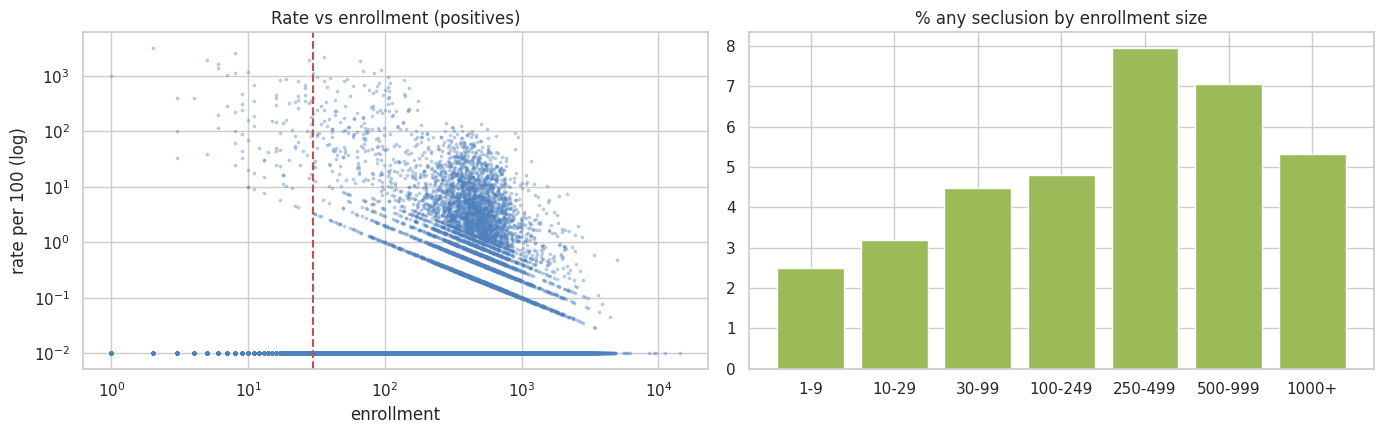

In [25]:
eb = pd.cut(df.enrollment_total, [0,9,29,99,249,499,999,1e6], labels=['1-9','10-29','30-99','100-249','250-499','500-999','1000+'])
g = df.groupby(eb, observed=True)
small = pd.DataFrame({'schools': g.size(), 'pct_any': g.any_secl.mean()*100,
    'median_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].median()),
    'p95_rate_if_any': g.apply(lambda s: s.loc[s.any_secl==1,'seclusion_rate'].quantile(.95)),
    'pct_rate_gt_100': g.apply(lambda s: (s.seclusion_rate>100).mean()*100),
    'pct_special_ed': g.type_sped.mean()*100})
print(small.round(2).to_string())
print(f'\nSchools under 30 students: {(df.enrollment_total<30).sum():,} ({(df.enrollment_total<30).mean():.1%}); they hold {df.loc[df.enrollment_total<30,"seclusion_instances"].sum()/df.seclusion_instances.sum():.1%} of instances but {(df.loc[df.seclusion_rate>100].enrollment_total<30).mean():.0%} of rate>100 schools')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(df.enrollment_total, df.seclusion_rate.clip(lower=.01), s=3, alpha=.3, color='#4f81bd'); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('enrollment'); ax[0].set_ylabel('rate per 100 (log)'); ax[0].set_title('Rate vs enrollment (positives)'); ax[0].axvline(30, color='r', ls='--')
ax[1].bar(small.index.astype(str), small.pct_any, color='#9bbb59'); ax[1].set_title('% any seclusion by enrollment size'); plt.tight_layout()

In [26]:
# Candidate smoothing: empirical-Bayes-style shrinkage toward the overall rate, k = pseudo-students
m0 = df.seclusion_instances.sum()/df.enrollment_total.sum()*100
for k in (30, 100): df[f'rate_eb_k{k}'] = (df.seclusion_instances + k*m0/100)/(df.enrollment_total + k)*100
top = lambda col, n=100: set(df.nlargest(n, col).combokey)
print(f'Overall rate m0 = {m0:.2f} per 100')
for col in ['seclusion_rate','rate_eb_k30','rate_eb_k100']:
    t = df.nlargest(100, col); print(f'{col:>14}: median enrollment of top-100 = {t.enrollment_total.median():.0f}; share with enrollment<30 = {(t.enrollment_total<30).mean():.0%}; share sped = {t.type_sped.mean():.0%}')
print('\nOverlap of top-100 raw vs EB(k=30):', len(top('seclusion_rate') & top('rate_eb_k30')), '| min-enrollment-30 raw top-100 vs EB(k=30):', len(set(df[df.enr_ge30].nlargest(100,'seclusion_rate').combokey) & top('rate_eb_k30')))

Overall rate m0 = 0.30 per 100
seclusion_rate: median enrollment of top-100 = 43; share with enrollment<30 = 37%; share sped = 76%
   rate_eb_k30: median enrollment of top-100 = 61; share with enrollment<30 = 26%; share sped = 77%
  rate_eb_k100: median enrollment of top-100 = 87; share with enrollment<30 = 18%; share sped = 69%

Overlap of top-100 raw vs EB(k=30): 88 | min-enrollment-30 raw top-100 vs EB(k=30): 74

## 10. 2017-18 vs 2021-22 (checklist 10) — **not possible from these files**
Only 2017-18 data was provided and this notebook is scoped to 2017-18. To complete this item later: (1) build the same cleaned frame for 2021-22 (and 2020-21 as a COVID sanity check only); (2) inner-join on `combokey` for schools present in both years; (3) compare `any_secl`, `seclusion_instances` and the rate, using a fixed minimum enrollment, and report the share of schools that move in/out of the elevated tier; (4) check that the `reserved_code` missingness behaves the same way before pooling years.

## 11. Equity patterns (checklist 11, descriptive only)
**Race and sex breakdowns of secluded students are not in the cleaned files** (only total instances split by IDEA / Section 504 / no-disability). The disability split is shown below; race/sex needs the raw CRDC columns to be carried through cleaning (see Data Issues).

                    instances       students  instances_per_100_students  share_of_instances_%  share_of_students_%  rate_ratio_vs_no_disability
IDEA (disability) 122,019.000  6,294,422.000                       1.939                85.936               13.175                       41.933
Section 504 only    1,399.000  1,308,332.000                       0.107                 0.985                2.739                        2.313
No disability      18,571.000 40,172,073.000                       0.046                13.079               84.086                        1.000

Same, regular schools only:
      instances       students  instances_per_100_students
IDEA 87,675.000  6,068,365.000                       1.445
504   1,371.000  1,288,666.000                       0.106
None 16,414.000 39,736,633.000                       0.041

Note: counts are seclusion INSTANCES (events), not unique students; one student can account for many instances.

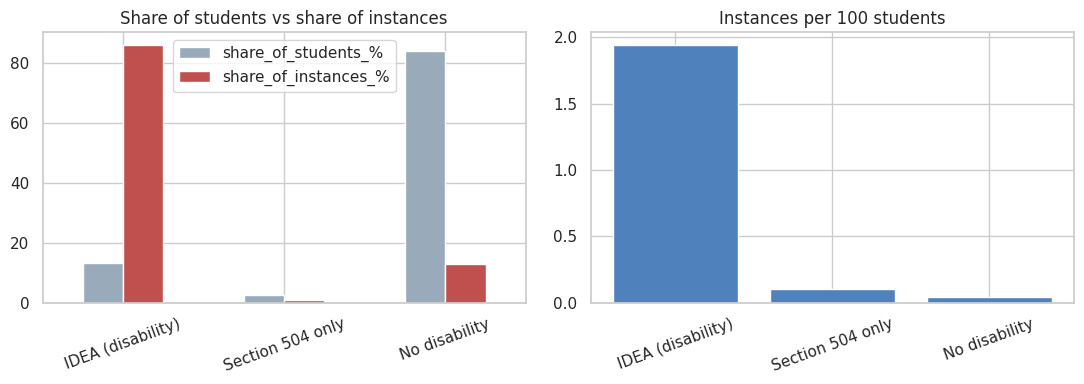

In [27]:
eq = df.dropna(subset=['enr_idea','enr_504','enrollment_total']).copy()
eq['enr_none'] = (eq.enrollment_total - eq.enr_idea - eq.enr_504).clip(lower=0)
def grp(inst, enr, d=eq):
    return pd.Series({'instances': d[inst].sum(), 'students': d[enr].sum(), 'instances_per_100_students': d[inst].sum()/d[enr].sum()*100})
equity = pd.DataFrame({'IDEA (disability)': grp('seclusion_instances_idea','enr_idea'), 'Section 504 only': grp('seclusion_instances_504','enr_504'), 'No disability': grp('seclusion_instances_wodis','enr_none')}).T
equity['share_of_instances_%'] = equity.instances/equity.instances.sum()*100; equity['share_of_students_%'] = equity.students/equity.students.sum()*100
equity['rate_ratio_vs_no_disability'] = equity.instances_per_100_students/equity.loc['No disability','instances_per_100_students']
print(equity.round(3).to_string())
excl = eq[~(eq.type_sped | eq.type_alt | eq.type_jj)]
eq2 = pd.DataFrame({'IDEA': grp('seclusion_instances_idea','enr_idea', excl), '504': grp('seclusion_instances_504','enr_504', excl), 'None': grp('seclusion_instances_wodis','enr_none', excl)}).T
print('\nSame, regular schools only:'); print(eq2.round(3).to_string())
print('\nNote: counts are seclusion INSTANCES (events), not unique students; one student can account for many instances.')
fig, ax = plt.subplots(1,2, figsize=(11,4)); equity[['share_of_students_%','share_of_instances_%']].plot.bar(ax=ax[0], color=['#9ab','#c0504d']); ax[0].set_title('Share of students vs share of instances'); ax[0].tick_params(axis='x', rotation=20)
ax[1].bar(equity.index, equity.instances_per_100_students, color='#4f81bd'); ax[1].set_title('Instances per 100 students'); ax[1].tick_params(axis='x', rotation=20); plt.tight_layout()

## 12. Correlations among candidate features (checklist 12)

,,rho
log_lea_enrollment,log_lea_schools,0.970
log_enrollment,fte_teachers,0.900
nurses_p100,support_fte_per_100,0.740
counselors_p100,fte_counselors,0.730
fte_teachers,fte_counselors,0.600
psych_p100,support_fte_per_100,0.570
social_p100,support_fte_per_100,0.560
log_enrollment,fte_counselors,0.530


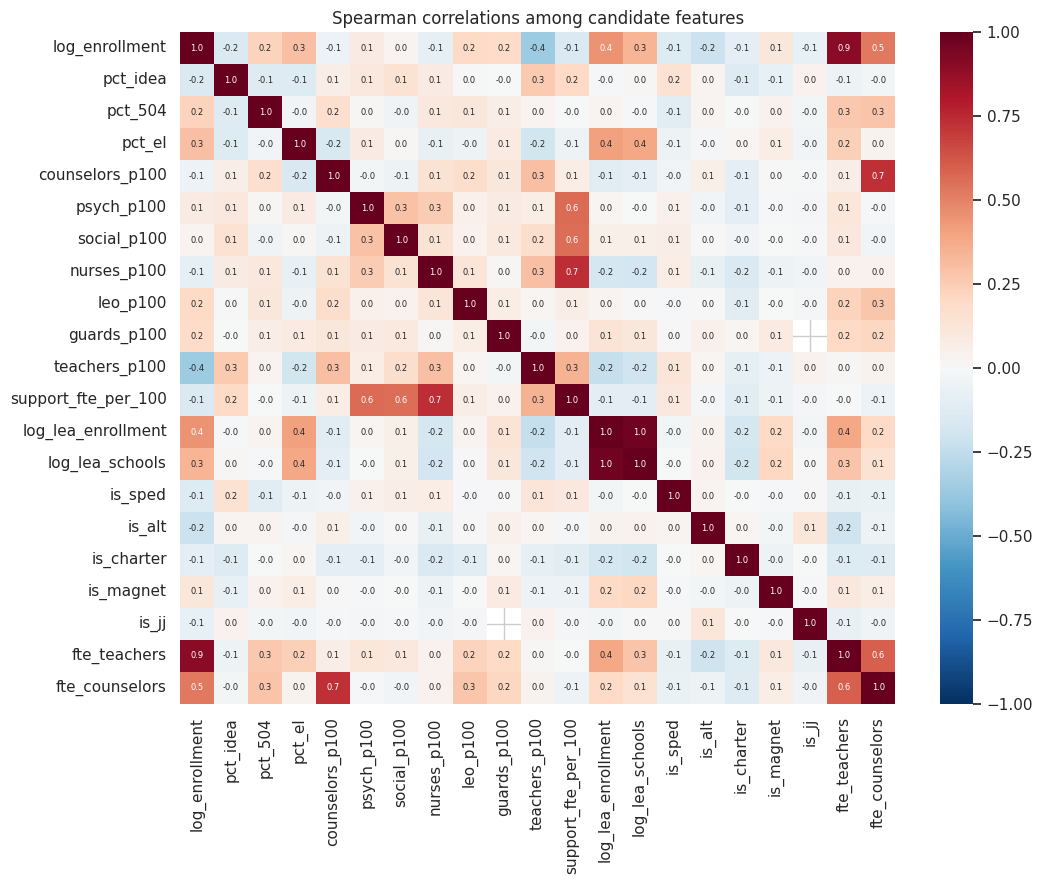

In [28]:
cand = df[df.enr_ge30 & ~df.flag_fte_outlier].copy()
cand['log_enrollment'] = np.log(cand.enrollment_total); cand['log_lea_enrollment'] = np.log(cand.lea_enrollment.clip(lower=1)); cand['log_lea_schools'] = np.log1p(cand.lea_schools)
for c in ['counselors','psych','social','nurses','leo','guards','teachers']:
    cand[f'{c}_p100'] = (cand[f'fte_{c}']/cand.enrollment_total*100); cand[f'{c}_p100'] = cand[f'{c}_p100'].clip(upper=cand[f'{c}_p100'].quantile(.995))
for c in ['sped','alt','charter','magnet','jj']: cand[f'is_{c}'] = cand[f'type_{c}'].astype(int)
feats = ['log_enrollment','pct_idea','pct_504','pct_el','counselors_p100','psych_p100','social_p100','nurses_p100','leo_p100','guards_p100','teachers_p100','support_fte_per_100',
         'log_lea_enrollment','log_lea_schools','is_sped','is_alt','is_charter','is_magnet','is_jj','fte_teachers','fte_counselors']
corr = cand[feats].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9)); sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size':6}, ax=ax); ax.set_title('Spearman correlations among candidate features'); plt.tight_layout()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename('rho'); pairs = pairs[pairs.abs()>=.5].sort_values(key=abs, ascending=False)
pairs.round(2)

## 13. Leakage review (checklist 13)

In [29]:
leak = pd.DataFrame([
 ('seclusion_instances_idea / _504 / _wodis', 'DIRECT LEAK', 'Components of the outcome (instances = their sum).'),
 ('seclusion_instances, seclusion_rate',        'DIRECT LEAK', 'The outcome itself / a deterministic transform of it.'),
 ('flag_missing_seclusion',                     'Exclude',     'Defines the sample; constant (False) in the analysis file.'),
 ('Other discipline measures (suspensions, expulsions, referrals, arrests)', 'POSSIBLE LEAK', 'Not in the cleaned files; same reporting module and same behavioural events. Exclude from the baseline model; if later tested, treat as a separate experiment.'),
 ('Restraint measures (mechanical / physical restraint)', 'POSSIBLE LEAK', 'Not in the cleaned files; reported together with seclusion in the same CRDC section; very likely co-reported. Exclude.'),
 ('fte_leo, fte_guards (security)',             'Reverse-causality risk', 'Schools with behaviour problems may hire security. Keep only if the model is framed as association, not prediction of future risk.'),
 ('lea_name, sch_name, leaid, combokey',        'Identifier', 'Not features. Use leaid only for grouped cross-validation.'),
], columns=['variable','status','why'])
print(leak.to_string(index=False))
print('\nAbsolute Spearman with any_secl, strongest first (enr>=30, no outliers):')
cc = cand[feats+['seclusion_instances_idea','seclusion_instances_wodis','seclusion_instances_504','any_secl']].corr(method='spearman')['any_secl'].drop('any_secl').abs().sort_values(ascending=False); print(cc.round(3).head(12).to_string())

                                                               variable                 status                                                                                                                                                            why
                               seclusion_instances_idea / _504 / _wodis            DIRECT LEAK                                                                                                             Components of the outcome (instances = their sum).
                                    seclusion_instances, seclusion_rate            DIRECT LEAK                                                                                                          The outcome itself / a deterministic transform of it.
                                                 flag_missing_seclusion                Exclude                                                                                                     Defines the sample; constant (False) in the

## 14. Baseline signal check: which feature groups carry information?
Grouped (by district) 5-fold cross-validation so schools of the same district never straddle train/test. Metric: ROC-AUC and average precision (the positive class is only ~6.6%, so AP matters). This is a signal check to inform the shortlist, not a final model.

In [30]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
mdl = cand.dropna(subset=['pct_idea','pct_504','pct_el']).copy()
for c in ['fte_leo','fte_guards']: pass
mdl = pd.concat([mdl, pd.get_dummies(mdl.grade_band, prefix='gb', dtype=float)], axis=1)
gb_cols = [c for c in mdl.columns if c.startswith('gb_')]
size = ['log_enrollment']; typ = ['is_sped','is_alt','is_charter','is_magnet','is_jj']+gb_cols
pop = ['pct_idea','pct_504','pct_el']; staffc = ['counselors_p100','psych_p100','social_p100','nurses_p100','teachers_p100']; sec = ['leo_p100','guards_p100']
lea = ['log_lea_enrollment','log_lea_schools']
mdl = pd.concat([mdl, pd.get_dummies(mdl.lea_state, prefix='st', dtype=float)], axis=1); st_cols = [c for c in mdl.columns if c.startswith('st_')]
sets = {'A size only': size, 'B + type & grade': size+typ, 'C + population shares': size+typ+pop, 'D + staffing': size+typ+pop+staffc,
        'E + security staff': size+typ+pop+staffc+sec, 'F + district size': size+typ+pop+staffc+sec+lea, 'G + state (one-hot)': size+typ+pop+staffc+sec+lea+st_cols}
y = mdl.any_secl.values; groups = mdl.leaid.values; res = []
for name, cols_ in sets.items():
    pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0))
    p = cross_val_predict(pipe, mdl[cols_], y, cv=GroupKFold(5), groups=groups, method='predict_proba')[:,1]
    res.append({'feature set': name, 'n_features': len(cols_), 'ROC_AUC': roc_auc_score(y, p), 'avg_precision': average_precision_score(y, p)})
base = pd.DataFrame(res).set_index('feature set'); print(f'rows={len(mdl):,}; positive rate={y.mean():.3%} (AP baseline = positive rate)'); base.round(3)

rows=87,591; positive rate=6.675% (AP baseline = positive rate)

,n_features,ROC_AUC,avg_precision
feature set,,,
A size only,1,0.563,0.078
B + type & grade,11,0.641,0.104
C + population shares,14,0.681,0.127
D + staffing,19,0.707,0.142
E + security staff,21,0.711,0.146
F + district size,23,0.729,0.148
G + state (one-hot),74,0.840,0.341


In [31]:
# Permutation importance (AUC drop) for the F model on a held-out grouped split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance
cols_ = sets['F + district size']; tr, te = next(GroupShuffleSplit(1, test_size=.25, random_state=1).split(mdl, y, groups))
pipe = make_pipeline(SimpleImputer(strategy='median'), HistGradientBoostingClassifier(max_iter=150, learning_rate=.08, max_depth=4, random_state=0)).fit(mdl.iloc[tr][cols_], y[tr])
pi = permutation_importance(pipe, mdl.iloc[te][cols_], y[te], scoring='roc_auc', n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=cols_).sort_values(ascending=False); print('held-out AUC:', round(roc_auc_score(y[te], pipe.predict_proba(mdl.iloc[te][cols_])[:,1]),3)); imp.round(4)

held-out AUC: 0.699

,0
log_lea_enrollment,0.027
pct_idea,0.027
teachers_p100,0.023
pct_504,0.021
gb_high,0.021
log_enrollment,0.015
psych_p100,0.014
social_p100,0.014
guards_p100,0.012
log_lea_schools,0.010


## 15. Data issues found during EDA (checklist deliverable 4)

In [32]:
fl = full[full.flag_fte_outlier]
issues = []
def add(i, sev, owner_item, n, detail): issues.append({'#': i, 'severity': sev, 'issue': owner_item, 'rows': n, 'detail': detail})
add(1,'High','sch_virt_ind is 100% empty', len(full), 'Virtual schools cannot be analysed; name-contains-virtual/online/cyber proxy used instead (%d schools in analysis file).' % df.type_virtual_name.sum())
add(2,'Med','enr_nonbinary is 100% empty', len(full), 'Column carries no information; drop or document.')
unfl = full[(~full.flag_fte_outlier) & ((full.fte_psych>50)|(full.fte_guards>100)|(full.fte_social>50)|(full.fte_nurses>50)|(full.fte_counselors>50)|(full.fte_teachers>300))]
add(3,'High','Impossible FTE values', int(len(fl)), f'flag_fte_outlier fires on {len(fl)} rows, but extreme values remain: max fte_psych={full.fte_psych.max():,.1f}, max fte_guards={full.fte_guards.max():,.0f}. Unflagged rows still above sanity limits (psych/social/nurse/counselor>50, guards>100, teachers>300): {len(unfl)}. Flagged rows are still present in the analysis file.')
add(4,'High','Seclusion missing set on total if ANY component is reserved', int(full.flag_missing_seclusion.sum()), f'{int(((full[comp].isna().sum(axis=1)).between(1,2)).sum())} schools have 1-2 components missing; {len(part)} of them have an observed component > 0 (a known lower bound that is discarded). Missingness also differs by type (special ed schools: higher).')
reg_ = df[df.regular]
add(5,'High','Extreme seclusion counts in mainstream schools', int((reg_.seclusion_instances>=100).sum()), f'{int((df.seclusion_instances>df.enrollment_total).sum())} analysis rows have more instances than students; {int((reg_.seclusion_rate>25).sum())} regular (non sped/alt/justice) schools exceed 25 instances per 100 students. Examples: Claiborne Pell Elementary (RI) 829 instances / 898 students; Urbana Middle (IL) 736 / 937; Whitman Elementary (WA) 622 / 562. Could be genuine (a few students secluded repeatedly) or entry errors; verify against the CRDC source before the top values are used as training labels.')
add(6,'Med','"seclusion_rate" naming/units', len(df), 'It is instances per 100 students (can exceed 100); name implies a proportion. Rename to seclusion_instances_per_100.')
add(7,'Med','Tiny enrollments', int((df.enrollment_total<10).sum()), 'Enrollment 1-9: rate and per-100 staffing ratios are unstable; flag_small_enrollment (<10) is not applied in analysis file and the cut-off is too low for rates (see section 9).')
add(8,'Med','enr_idea > enrollment_total', int((full.enr_idea>full.enrollment_total).sum()), 'Impossible; cleaning sets pct_idea to NA for these 222 rows (matches log) but keeps enr_idea itself, so enr_idea should not be used raw. Remaining pct_idea max = %.1f.' % full.pct_idea.max())
add(9,'Low','Flags that never fire', 6, 'flag_partial_enrollment/idea/504/el, flag_missing_module, flag_missing_lea are all False — remove or confirm they are implemented.')
add(10,'Low','Quality-log entry with no school key', int(qlog.combokey.isna().sum()), 'One LEA-level entry (LEA_ENR reserved code -5, LEAID 2509360) has no combokey. Expected, but document that the log is not 100% joinable to the schools file.')
add(11,'High','Race / sex of secluded students not carried through cleaning', 0, 'Required for the equity checklist item; also other discipline/restraint columns needed for the leakage review are absent.')
add(12,'Low','fte_leo / fte_guards missing', int(full.fte_leo.isna().sum()+full.fte_guards.isna().sum()), '1.7% / 2.3% missing (reserved codes); decide on imputing 0 vs NA.')
add(13,'Med','State coverage and reporting practice', 0, f'{full.lea_state.nunique()} state codes (incl. DC and PR); confirm intended universe. Puerto Rico has {int((df.lea_state=="PR").sum())} schools and zero reported seclusion; several states (CA, TX, NV, PA, NY...) are below 1% of schools reporting any, so cross-state differences mix real practice with state law / reporting definitions.')
pd.DataFrame(issues).set_index('#')

,severity,issue,rows,detail
#,,,,
1,High,sch_virt_ind is 100% empty,97632,Virtual schools cannot be analysed; name-contains-virtual/online/cyber proxy used instead (427 schools in analysis file).
2,Med,enr_nonbinary is 100% empty,97632,Column carries no information; drop or document.
3,High,Impossible FTE values,68,"flag_fte_outlier fires on 68 rows, but extreme values remain: max fte_psych=19,048.6, max fte_guards=102,579. Unflagged rows still above sanity limits (psych/social/nurse/counselor>50, guards>100, teachers>300): 11. Flagged rows are still present in the analysis file."
4,High,Seclusion missing set on total if ANY component is reserved,6619,690 schools have 1-2 components missing; 226 of them have an observed component > 0 (a known lower bound that is discarded). Missingness also differs by type (special ed schools: higher).
5,High,Extreme seclusion counts in mainstream schools,236,155 analysis rows have more instances than students; 226 regular (non sped/alt/justice) schools exceed 25 instances per 100 students. Examples: Claiborne Pell Elementary (RI) 829 instances / 898 students; Urbana Middle (IL) 736 / 937; Whitman Elementary (WA) 622 / 562. Could be genuine (a few students secluded repeatedly) or entry errors; verify against the CRDC source before the top values are used as training labels.
6,Med,"""seclusion_rate"" naming/units",91013,It is instances per 100 students (can exceed 100); name implies a proportion. Rename to seclusion_instances_per_100.
7,Med,Tiny enrollments,1041,Enrollment 1-9: rate and per-100 staffing ratios are unstable; flag_small_enrollment (<10) is not applied in analysis file and the cut-off is too low for rates (see section 9).
8,Med,enr_idea > enrollment_total,222,"Impossible; cleaning sets pct_idea to NA for these 222 rows (matches log) but keeps enr_idea itself, so enr_idea should not be used raw. Remaining pct_idea max = 100.0."
9,Low,Flags that never fire,6,"flag_partial_enrollment/idea/504/el, flag_missing_module, flag_missing_lea are all False — remove or confirm they are implemented."


## 16. Key findings (2017-18)
1. **Data are complete enough, with one important hole.** 97,632 schools; 91,013 (93.2%) are analysis-ready. The 6,619 dropped schools lose the outcome because any reserved-code component blanks the total (226 of them had an observed component above zero). Dropped schools are more often special-education schools (5.6% vs 2.0%) and have higher %IDEA, so the analysis file under-represents the highest-risk schools.
2. **Seclusion is rare and extremely skewed.** 93.4% of schools report zero; 6.56% (5,975) report at least one instance. Among those, the median is 5 instances, the 90th percentile is 54 and the maximum 1,252. The top 100 schools hold 30% of all instances; the top 500 hold 63%.
3. **Reporting context dominates.** State alone separates positives from zeros with ROC-AUC 0.81. Wisconsin, Iowa, Maine, Connecticut and Kansas have 23-33% of schools reporting any seclusion; California, Texas, Nevada, Pennsylvania, New York and others are under 1.2%, and Puerto Rico reports none. These gaps reflect state law/definitions and reporting practice as well as real differences. Adding state to the baseline model lifts average precision from 0.15 to 0.34.
4. **Concentrated in few districts.** Only 12.9% of districts have any school reporting seclusion; 89 districts account for half of all instances and 339 for 80%. Regional special-education cooperatives (e.g. SE Cooperative Ed Program, VA; Montgomery County ESC, OH) have a handful of schools with extreme counts.
5. **School type.** Special-education schools: 16.6% report any (vs 6.4%) and hold 23.5% of instances while being 2% of schools; justice facilities 7.9%. Alternative (2.0%), charter (2.8%), magnet (4.7%) and name-proxy virtual (0.5%) schools are lower. Elementary schools are highest (8.9%; the 257 'other' schools reach 10.5%), then span (6.5%), middle (5.1%) and high (2.9%). 93% of positive schools are ordinary schools, so the signal is not just a special-ed artifact.
6. **Student population.** %IDEA is the clearest positive correlate (2.1% any at under 5% IDEA, 8.5% at 15-20%), though it flattens or falls above 30% IDEA (where special-ed schools sit). %504 is negative at high levels and %EL is inverted-U. All pairwise rank correlations with the outcome are weak (|rho| <= 0.07), so these are modest signals.
7. **Staffing.** Relationships are non-monotonic and confounded by size and school need. Schools with psychologists or social workers report more seclusion; schools with high counselor or security staffing per 100 report less. After adjusting for size, grade, and population, psychologists remain slightly positive and security guards negative; counselors, nurses and social workers add almost nothing. Security and support staff may respond to behaviour problems (reverse causality), so these are associations, not causes.
8. **Small enrollments distort rates.** Schools under 30 students are 3.5% of schools and 2.9% of instances but 31% of the schools with rates above 100 per 100 students. Median rate among positives is 265 per 100 for enrollments of 1-9 and 25 for 30-99, versus 1.4 for 250-499. A minimum enrollment of 30 plus shrinkage (k about 30-100 pseudo-students) stabilises rates.
9. **Equity (disability only).** Students with IDEA are 13.2% of enrolled students but account for 85.9% of instances: 1.94 instances per 100 students versus 0.046 for students without a disability, a 42x gap (35x in regular schools). Section 504-only students are at 0.107 (2.3x). Instances are events, not students. Race and sex could not be assessed from the cleaned files.
10. **Redundant features.** District enrollment and district school count (rho 0.97); school enrollment and teacher FTE (0.90); counselors per 100 and counselor FTE (0.73); nurses per 100 and the combined support ratio (0.74).
11. **Leakage.** The three seclusion component counts and the rate are the outcome. Other discipline and restraint measures were not in the cleaned files, so leakage could not be tested directly; they should stay out of the baseline model.
12. **Not done here:** the 2017-18 vs 2021-22 comparison (section 10) and race/sex equity (section 11) need data that was not supplied.

## 17. Recommended target definition
| | Definition | Prevalence | Use |
|---|---|---|---|
| **Primary: `any_seclusion`** | `seclusion_instances >= 1` | 6.6% of analysis-ready schools | Main classification target. Robust to enrollment, avoids the unstable rate. |
| **Secondary: `elevated_seclusion`** | `seclusion_instances >= 5` **and** `seclusion_rate >= 1` (per 100 students) | 3.1% of schools with enrollment >= 30 | Sensitivity analysis / second model. Five instances covers 96% of all instances and removes one-off events; the rate floor keeps large schools from qualifying on volume alone. |
| Not recommended | Raw `seclusion_rate` or raw count as regression target | | 93% zeros, heavy tail (max 3,250 per 100), denominator-driven for small schools. |

**Modeling frame:** analysis-ready rows with `enrollment_total >= 30` (drops 3,230 schools, 3.5%). For any rate-based work add shrinkage (k ~ 30-100) or use counts with log(enrollment) as an offset. Exclude the 68 `flag_fte_outlier` rows. Use grouped cross-validation by district (`leaid`).

In [33]:
shortlist = pd.DataFrame([
 # feature, group, decision, reason
 ('log(enrollment_total)', 'Size', 'Include', 'Strongest scale effect; needed because instances scale with students.'),
 ('grade_band', 'School type', 'Include', 'Elementary 8.9% vs high 2.9% any seclusion; holds in regular schools.'),
 ('sch_status_sped', 'School type', 'Include', '16.6% vs 6.4% any; 23.5% of instances.'),
 ('sch_status_alt', 'School type', 'Include', 'Lower rate, distinct population; low redundancy.'),
 ('sch_status_charter', 'School type', 'Include', '2.8% vs 6.9% any; small but stable effect.'),
 ('jj (justice facility)', 'School type', 'Include', 'Small group (555) but extreme rates when positive.'),
 ('sch_status_magnet', 'School type', 'Optional', 'Weak signal in permutation importance.'),
 ('pct_idea', 'Population', 'Include', 'Clearest positive correlate; top permutation importance. Use cleaned pct_idea (NA where enr_idea > enrollment).'),
 ('pct_504', 'Population', 'Include', 'Negative at high levels; moderate importance.'),
 ('pct_el', 'Population', 'Include', 'Inverted-U; weak but independent of IDEA.'),
 ('psych_per_100, social_per_100', 'Staffing', 'Include', 'Positive association after adjustment; compute from FTE / enrollment, capped at 99.5th pct.'),
 ('counselors_per_100, nurses_per_100', 'Staffing', 'Optional', 'Near-zero adjusted effect; keep for completeness.'),
 ('teachers_per_100', 'Staffing', 'Optional', 'Moderate permutation importance but unstable for tiny schools; check with min enrollment 30.'),
 ('fte_leo / fte_guards per 100', 'Security', 'Optional (caution)', 'Negative association; likely reverse causality; use only if framed as association.'),
 ('log(lea_enrollment)', 'District context', 'Include', 'Top permutation importance among context features; drop lea_schools (rho 0.97).'),
 ('lea_state (categorical / region)', 'Context', 'Include in a second model', 'Dominant signal (AUC 0.73 -> 0.84) reflecting reporting practice; run models with and without it and report both.'),
 ('fte_teachers, fte_counselors (raw counts)', 'Staffing', 'Drop', 'Redundant with enrollment (rho 0.90 / 0.53).'),
 ('support_fte_per_100', 'Staffing', 'Drop', 'Composite of components already included; unclear derivation (corr 0.85 with rebuilt sum).'),
 ('lea_schools', 'District context', 'Drop', 'rho 0.97 with log(lea_enrollment).'),
 ('seclusion_instances_idea/_504/_wodis, seclusion_instances, seclusion_rate', 'Outcome', 'EXCLUDE (leak)', 'Direct components/transforms of the target.'),
 ('Other discipline and restraint measures', 'Behaviour', 'EXCLUDE (leak risk)', 'Not in cleaned files; same reporting section and events.'),
 ('enr_nonbinary, sch_virt_ind', 'Empty', 'Drop', '100% missing.'),
 ('lea_name, sch_name, leaid, combokey', 'Identifier', 'Not features', 'Use leaid for grouped CV only.'),
], columns=['feature','group','decision','reason'])
shortlist

,feature,group,decision,reason
0,log(enrollment_total),Size,Include,Strongest scale effect; needed because instances scale with students.
1,grade_band,School type,Include,Elementary 8.9% vs high 2.9% any seclusion; holds in regular schools.
2,sch_status_sped,School type,Include,16.6% vs 6.4% any; 23.5% of instances.
3,sch_status_alt,School type,Include,"Lower rate, distinct population; low redundancy."
4,sch_status_charter,School type,Include,2.8% vs 6.9% any; small but stable effect.
5,jj (justice facility),School type,Include,Small group (555) but extreme rates when positive.
6,sch_status_magnet,School type,Optional,Weak signal in permutation importance.
7,pct_idea,Population,Include,Clearest positive correlate; top permutation importance. Use cleaned pct_idea (NA where enr_idea > enrollment).
8,pct_504,Population,Include,Negative at high levels; moderate importance.
9,pct_el,Population,Include,Inverted-U; weak but independent of IDEA.


In [34]:
OUT_DIR = Path('/mnt/user-data/outputs'); OUT_DIR.mkdir(parents=True, exist_ok=True)
shortlist.to_csv(OUT_DIR/'feature_shortlist_201718.csv', index=False)
pd.DataFrame(issues).to_csv(OUT_DIR/'data_issues_201718.csv', index=False)
frame = df[(df.enrollment_total >= 30) & ~df.flag_fte_outlier].copy()
frame['elevated_seclusion'] = ((frame.seclusion_instances >= 5) & (frame.seclusion_rate >= 1)).astype(int)
print(f"Modeling frame: {len(frame):,} schools | any_seclusion prevalence {frame.any_secl.mean():.2%} | elevated_seclusion prevalence {frame.elevated_seclusion.mean():.2%} ({frame.elevated_seclusion.sum():,} schools)")

Modeling frame: 87,718 schools | any_seclusion prevalence 6.70% | elevated_seclusion prevalence 3.09% (2,710 schools)